In [1]:
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import numpy as np

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay
)


In [2]:
# ============================================================
# 1. PARÂMETROS DO MLP
# ============================================================

MLP_PARAMS = {
    # Arquitetura da rede
    "hidden_layer_sizes": (64, 32, 16),

    # Função de ativação dos neurônios
    "activation": "tanh",

    # Algoritmo de otimização
    "solver": "sgd",

    # Taxa de aprendizado inicial
    "learning_rate_init": 0.001,

    # Quantidade máxima de épocas
    "max_iter": 100,

    # Tamanho do lote utilizado no treinamento
    "batch_size": 64,

    # Regularização L2
    "alpha": 0.0001,

    # Para interromper quando não houver melhoria
    "early_stopping": False,

    # Reprodutibilidade
    "random_state": 42
}

THRESHOLD = 0.90

In [3]:
# ============================================================
# 2. CARREGAMENTO DO DATASET
# ============================================================

arquivo = "C:/Users/gques/Documents/SPTECH_CODIGOS/ultimo-ano/tcc/backend/tabela_final/table_orders_holidays_ecommerce_events.csv"


df = pd.read_csv(arquivo)

In [4]:


target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier",
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    # "had_ecommerce_event_14_days_ago",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",
    "customer_city",
    "seller_city",
    "category_name"
]

X = X.drop(columns=colunas_remover, errors='ignore')

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()


# ============================================================
# 10. HOLD-OUT TEMPORAL
# ============================================================

# Data de corte do teste independente.
split_date = pd.to_datetime("2018-07-01", utc=True)

# Data de corte da validação.
val_split_date = pd.to_datetime("2018-05-01", utc=True)

# Converter datas de entrega para datetime.
customer_dates = pd.to_datetime(
    df["order_delivered_customer_date"],
    utc=True
)

carrier_dates = pd.to_datetime(
    df["order_delivered_carrier_date"],
    utc=True
)

# ------------------------------------------------------------
# 1. EXPURGO NA FRONTEIRA ENTRE TREINO E TESTE
# ------------------------------------------------------------

# Remove pedidos coletados antes de julho,
# mas entregues em julho ou posteriormente.

mask_treino_limpo = (
    (date_col < split_date) &
    (customer_dates < split_date)
)

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

# Aplica o expurgo somente no treinamento.
X_train = X_train.loc[mask_treino_limpo].copy()
y_train = y_train.loc[mask_treino_limpo].copy()

# ------------------------------------------------------------
# 2. HOLD-OUT TEMPORAL: TREINO DE TUNING E VALIDAÇÃO
# ------------------------------------------------------------

carrier_train_dates = carrier_dates.loc[X_train.index]
customer_train_dates = customer_dates.loc[X_train.index]

# Treinamento de tuning:
# coleta e entrega anteriores a maio de 2018.

tr_mask_tune = (
    (carrier_train_dates < val_split_date) &
    (customer_train_dates < val_split_date)
)

# Validação:
# pedidos coletados a partir de maio de 2018.

va_mask_tune = (
    carrier_train_dates >= val_split_date
)

# Quantidade de pedidos expurgados na fronteira de maio.
n_expurgados_val = int(
    (
        (carrier_train_dates < val_split_date) &
        (customer_train_dates >= val_split_date)
    ).sum()
)

# Mantém apenas treinamento e validação sem sobreposição.
train_clean_mask = tr_mask_tune | va_mask_tune

X_train = X_train.loc[train_clean_mask].copy()
y_train = y_train.loc[train_clean_mask].copy()

carrier_train_dates = carrier_train_dates.loc[train_clean_mask]

# ------------------------------------------------------------
# 3. SEPARAÇÃO DOS CONJUNTOS
# ------------------------------------------------------------

tr_idx = np.where(
    (carrier_train_dates < val_split_date).values
)[0]

va_idx = np.where(
    (carrier_train_dates >= val_split_date).values
)[0]

X_treino_busca = X_train.iloc[tr_idx].copy()
y_treino_busca = y_train.iloc[tr_idx].copy()

X_validacao = X_train.iloc[va_idx].copy()
y_validacao = y_train.iloc[va_idx].copy()

# ------------------------------------------------------------
# 4. NORMALIZAÇÃO PARA A VALIDAÇÃO
# ------------------------------------------------------------

# O scaler aprende somente com o treino de tuning.
scaler_busca = StandardScaler()

X_treino_busca_scaled = pd.DataFrame(
    scaler_busca.fit_transform(X_treino_busca),
    columns=X_treino_busca.columns,
    index=X_treino_busca.index
)

X_validacao_scaled = pd.DataFrame(
    scaler_busca.transform(X_validacao),
    columns=X_validacao.columns,
    index=X_validacao.index
)

# ------------------------------------------------------------
# 5. ESTATÍSTICAS DA DIVISÃO
# ------------------------------------------------------------

qtd_tr_tune = len(X_treino_busca)
qtd_va_tune = len(X_validacao)

qtd_treino = len(X_train)
qtd_teste = len(X_test)

total_linhas = len(X)

atrasos_tr_tune = int((y_treino_busca == 1).sum())
atrasos_va_tune = int((y_validacao == 1).sum())

n_expurgados_julho = int(
    (
        (date_col < split_date) &
        (customer_dates >= split_date)
    ).sum()
)

carrier_test_dates = carrier_dates.loc[X_test.index]

print("=" * 100)
print("DISTRIBUIÇÃO DOS DADOS - HOLD-OUT TEMPORAL")
print("=" * 100)

print(f"Total de registros: {total_linhas:,}\n")

print("1. SEPARAÇÃO GERAL")
print("-" * 100)

print(f"Treino completo: {qtd_treino:,}")
print(f"Atrasos no treino: {(y_train == 1).sum():,}")
print(f"Expurgados na fronteira de julho: {n_expurgados_julho:,}\n")

print(f"Teste independente: {qtd_teste:,}")
print(f"Atrasos no teste: {(y_test == 1).sum():,}\n")

print("2. HOLD-OUT TEMPORAL")
print("-" * 100)

print(f"Treino de tuning: {qtd_tr_tune:,}")
print(
    f"Período: {carrier_train_dates.iloc[tr_idx].min():%d/%m/%Y} "
    f"a {carrier_train_dates.iloc[tr_idx].max():%d/%m/%Y}"
)
print(f"Atrasos: {atrasos_tr_tune:,}")

print(f"Pedidos expurgados na fronteira de maio: {n_expurgados_val:,}\n")

print(f"Validação: {qtd_va_tune:,}")
print(
    f"Período: {carrier_train_dates.iloc[va_idx].min():%d/%m/%Y} "
    f"a {carrier_train_dates.iloc[va_idx].max():%d/%m/%Y}"
)
print(f"Atrasos: {atrasos_va_tune:,}")

print("=" * 100)

X_test.head()


DISTRIBUIÇÃO DOS DADOS - HOLD-OUT TEMPORAL
Total de registros: 33,603

1. SEPARAÇÃO GERAL
----------------------------------------------------------------------------------------------------
Treino completo: 28,092
Atrasos no treino: 1,293
Expurgados na fronteira de julho: 195

Teste independente: 5,000
Atrasos no teste: 499

2. HOLD-OUT TEMPORAL
----------------------------------------------------------------------------------------------------
Treino de tuning: 23,209
Período: 08/10/2016 a 27/04/2018
Atrasos: 1,139
Pedidos expurgados na fronteira de maio: 316

Validação: 4,883
Período: 02/05/2018 a 29/06/2018
Atrasos: 154


,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,had_ecommerce_event_14_days_ago,...,freight_value,product_weight_g,volume_cm3,distance_km,same_city,prazo_transportadora_dias,carrier_month,prazo_por_km,frete_por_kg,densidade_produto
28603,0,32,7,0,50,41,0,0,0,0,...,13.07,200,3960.0,65.936,0,16,7,0.239034,43.566667,0.050492
28604,0,32,7,0,50,41,0,0,0,0,...,13.76,2350,10648.0,411.255,0,16,7,0.038811,5.616327,0.220678
28605,0,32,7,0,50,41,0,0,0,0,...,13.50,459,3276.0,284.778,0,20,7,0.069984,24.150268,0.140067
28606,0,32,7,0,50,41,0,0,0,0,...,13.00,250,640.0,221.179,0,17,7,0.076515,37.142857,0.390016
28607,0,32,7,0,50,41,0,0,0,0,...,17.95,3305,35100.0,112.930,0,10,7,0.087773,5.271659,0.094157



AVALIAÇÃO NA VALIDAÇÃO TEMPORAL
Accuracy:  0.9689
Precision: 1.0000
Recall:    0.0130
F1:        0.0256
F2:        0.0162
ROC-AUC:   0.8122
PR-AUC:    0.2378

Épocas executadas: 100


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


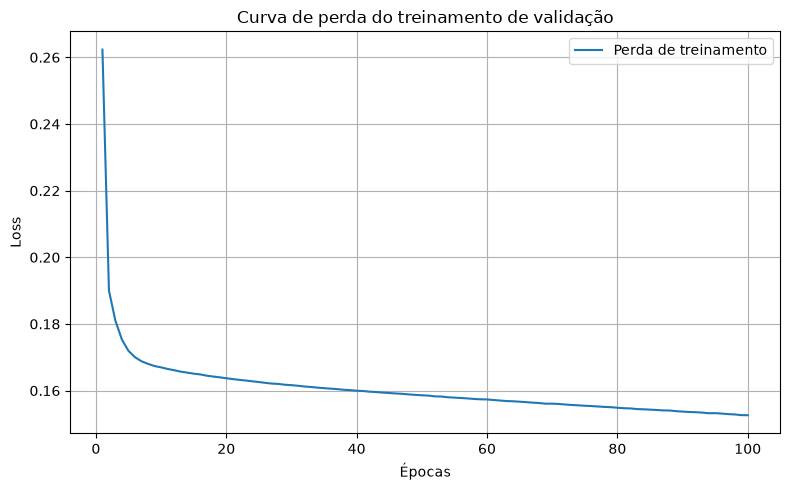

In [5]:

# ============================================================
# 11. TREINAMENTO E AVALIAÇÃO NA VALIDAÇÃO
# ============================================================

print("\n" + "=" * 70)
print("AVALIAÇÃO NA VALIDAÇÃO TEMPORAL")
print("=" * 70)

# Cria o MLP com os parâmetros definidos.
mlp_validacao = MLPClassifier(
    **MLP_PARAMS
)

# Treina somente com o conjunto de tuning.
mlp_validacao.fit(
    X_treino_busca_scaled,
    y_treino_busca
)

# Probabilidades de atraso na validação.
y_prob_validacao = mlp_validacao.predict_proba(
    X_validacao_scaled
)[:, 1]

# Aplica o limiar definido.
y_pred_validacao = (
    y_prob_validacao >= THRESHOLD
).astype(int)

# Métricas da validação.
accuracy_validacao = accuracy_score(
    y_validacao,
    y_pred_validacao
)

precision_validacao = precision_score(
    y_validacao,
    y_pred_validacao,
    zero_division=0
)

recall_validacao = recall_score(
    y_validacao,
    y_pred_validacao,
    zero_division=0
)

f1_validacao = f1_score(
    y_validacao,
    y_pred_validacao,
    zero_division=0
)

f2_validacao = fbeta_score(
    y_validacao,
    y_pred_validacao,
    beta=2,
    zero_division=0
)

roc_auc_validacao = roc_auc_score(
    y_validacao,
    y_prob_validacao
)

precision_pr, recall_pr, _ = precision_recall_curve(
    y_validacao,
    y_prob_validacao
)

pr_auc_validacao = auc(
    recall_pr,
    precision_pr
)

print(f"Accuracy:  {accuracy_validacao:.4f}")
print(f"Precision: {precision_validacao:.4f}")
print(f"Recall:    {recall_validacao:.4f}")
print(f"F1:        {f1_validacao:.4f}")
print(f"F2:        {f2_validacao:.4f}")
print(f"ROC-AUC:   {roc_auc_validacao:.4f}")
print(f"PR-AUC:    {pr_auc_validacao:.4f}")

print(
    f"\nÉpocas executadas: {mlp_validacao.n_iter_}"
)



# ============================================================
# 13. GRÁFICO DE PERDA DO TREINAMENTO DE VALIDAÇÃO
# ============================================================

epocas = range(1, len(mlp_validacao.loss_curve_) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epocas,
    mlp_validacao.loss_curve_,
    label="Perda de treinamento"
)

plt.title("Curva de perda do treinamento de validação")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Gráfico 01
A curva de perda mostra o erro que o modelo apresenta durante o treinamento.

Curva decrescente: o modelo está aprendendo a ajustar seus pesos.

Curva estabilizada: o treinamento pode ter atingido um platô.

Curva crescente: pode indicar instabilidade ou dificuldades de otimização.

# Gráfico 02

A curva de validação mostra como o modelo classifica as amostras reservadas para validação durante o treinamento.

Acurácia crescente: o modelo está melhorando sua capacidade de classificação no conjunto de validação.

Acurácia estabilizada: pode indicar que o modelo deixou de apresentar melhorias.

Acurácia decrescente: pode indicar que o modelo está perdendo capacidade de generalização.


TREINAMENTO FINAL


Épocas executadas no modelo final: 100

Modelo salvo com sucesso em: C:/Users/gques/Documents/SPTECH_CODIGOS/ultimo-ano/tcc/backend/modelo/dl/modelo_mlp_v1.pkl


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


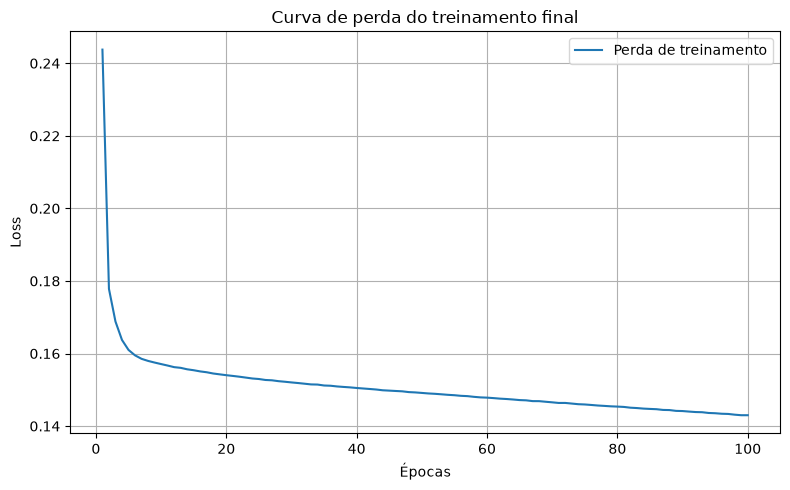

In [6]:

# ============================================================
# 12. TREINAMENTO FINAL COM TODO O CONJUNTO DE TREINO
# ============================================================

print("\n" + "=" * 70)
print("TREINAMENTO FINAL")
print("=" * 70)

# Novo StandardScaler ajustado com todo o treinamento.
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Criação do modelo definitivo.
mlp = MLPClassifier(
    **MLP_PARAMS
)

# Treinamento com todos os dados disponíveis até junho.
mlp.fit(
    X_train_scaled,
    y_train
)

print(
    f"Épocas executadas no modelo final: {mlp.n_iter_}"
)

# ============================================================
# 12.1 SALVAMENTO DO MODELO
# ============================================================

modelo = {
    "model": mlp,
    "scaler": scaler,
    "features": X_train.columns.tolist(),
    "threshold": THRESHOLD
}

caminho_modelo = "C:/Users/gques/Documents/SPTECH_CODIGOS/ultimo-ano/tcc/backend/modelo/dl/modelo_mlp_v1.pkl"

with open(caminho_modelo, "wb") as arquivo:
    pickle.dump(modelo, arquivo)

print(f"\nModelo salvo com sucesso em: {caminho_modelo}")

# ============================================================
# 13. GRÁFICO DE PERDA DO TREINAMENTO FINAL
# ============================================================

epocas = range(1, len(mlp.loss_curve_) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epocas,
    mlp.loss_curve_,
    label="Perda de treinamento"
)

plt.title("Curva de perda do treinamento final")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# 12. PREDIÇÃO
# ============================================================

y_prob = mlp.predict_proba(
    X_test_scaled
)[:, 1]

y_pred = (
    y_prob >= THRESHOLD
).astype(int)

In [8]:
# ============================================================
# 13. MÉTRICAS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision_atraso = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall_atraso = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1_atraso = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f2_atraso = fbeta_score(
    y_test,
    y_pred,
    beta=2,
    pos_label=1,
    zero_division=0
)

roc_auc_atraso = roc_auc_score(
    y_test,
    y_prob
)

precision_pr, recall_pr, _ = precision_recall_curve(
    y_test,
    y_prob,
    pos_label=1
)

pr_auc_atraso = auc(
    recall_pr,
    precision_pr
)


RESULTADOS - MLP
Arquitetura: (64, 32, 16)
Activation: tanh
Solver: sgd
Learning rate: 0.001
Batch size: 64
Épocas máximas: 100
Limiar: 0.90

Quantidade de amostras:
Treino: 28092
Teste:  5000

Métricas:
Accuracy:        0.9030
Precision atraso: 0.8182
Recall atraso:    0.0361
F1 atraso:        0.0691
F2 atraso:        0.0446
ROC-AUC atraso:   0.8599
PR-AUC atraso:    0.4483

Como interpretar as métricas:
- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- F1 atraso: média harmônica entre precision e recall.
- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.
- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.
- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.


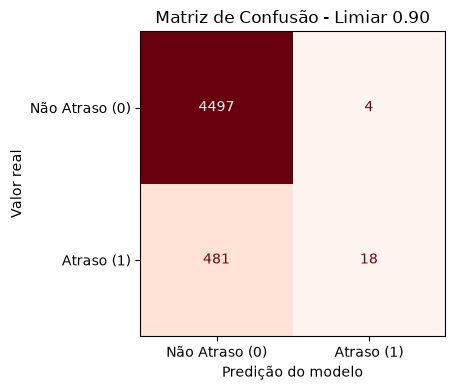


Relatório de classificação:
                precision    recall  f1-score   support

Não Atraso (0)       0.90      1.00      0.95      4501
    Atraso (1)       0.82      0.04      0.07       499

      accuracy                           0.90      5000
     macro avg       0.86      0.52      0.51      5000
  weighted avg       0.89      0.90      0.86      5000


Quantidade de épocas executadas:
100


In [9]:
# ============================================================
# 14. RESULTADOS
# ============================================================

print("\n" + "=" * 60)
print("RESULTADOS - MLP")
print("=" * 60)

print(f"Arquitetura: {MLP_PARAMS['hidden_layer_sizes']}")
print(f"Activation: {MLP_PARAMS['activation']}")
print(f"Solver: {MLP_PARAMS['solver']}")
print(f"Learning rate: {MLP_PARAMS['learning_rate_init']}")
print(f"Batch size: {MLP_PARAMS['batch_size']}")
print(f"Épocas máximas: {MLP_PARAMS['max_iter']}")
print(f"Limiar: {THRESHOLD:.2f}")

print("\nQuantidade de amostras:")
print(f"Treino: {len(X_train)}")
print(f"Teste:  {len(X_test)}")

print("\nMétricas:")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Precision atraso: {precision_atraso:.4f}")
print(f"Recall atraso:    {recall_atraso:.4f}")
print(f"F1 atraso:        {f1_atraso:.4f}")
print(f"F2 atraso:        {f2_atraso:.4f}")
print(f"ROC-AUC atraso:   {roc_auc_atraso:.4f}")
print(f"PR-AUC atraso:    {pr_auc_atraso:.4f}")

# ============================================================
# INTERPRETAÇÃO DAS MÉTRICAS
# ============================================================

print("\nComo interpretar as métricas:")
print("- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- F1 atraso: média harmônica entre precision e recall.")
print("- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.")
print("- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.")
print("- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.")

# ============================================================
# MATRIZ DE CONFUSÃO
# ============================================================

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Reds",
    ax=ax,
    colorbar=False,
    display_labels=[
        "Não Atraso (0)",
        "Atraso (1)"
    ]
)

ax.set_title(
    f"Matriz de Confusão - Limiar {THRESHOLD:.2f}"
)

ax.set_xlabel("Predição do modelo")
ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# ============================================================
# RELATÓRIO DE CLASSIFICAÇÃO
# ============================================================

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Não Atraso (0)",
            "Atraso (1)"
        ],
        zero_division=0
    )
)

print("\nQuantidade de épocas executadas:")
print(mlp.n_iter_)